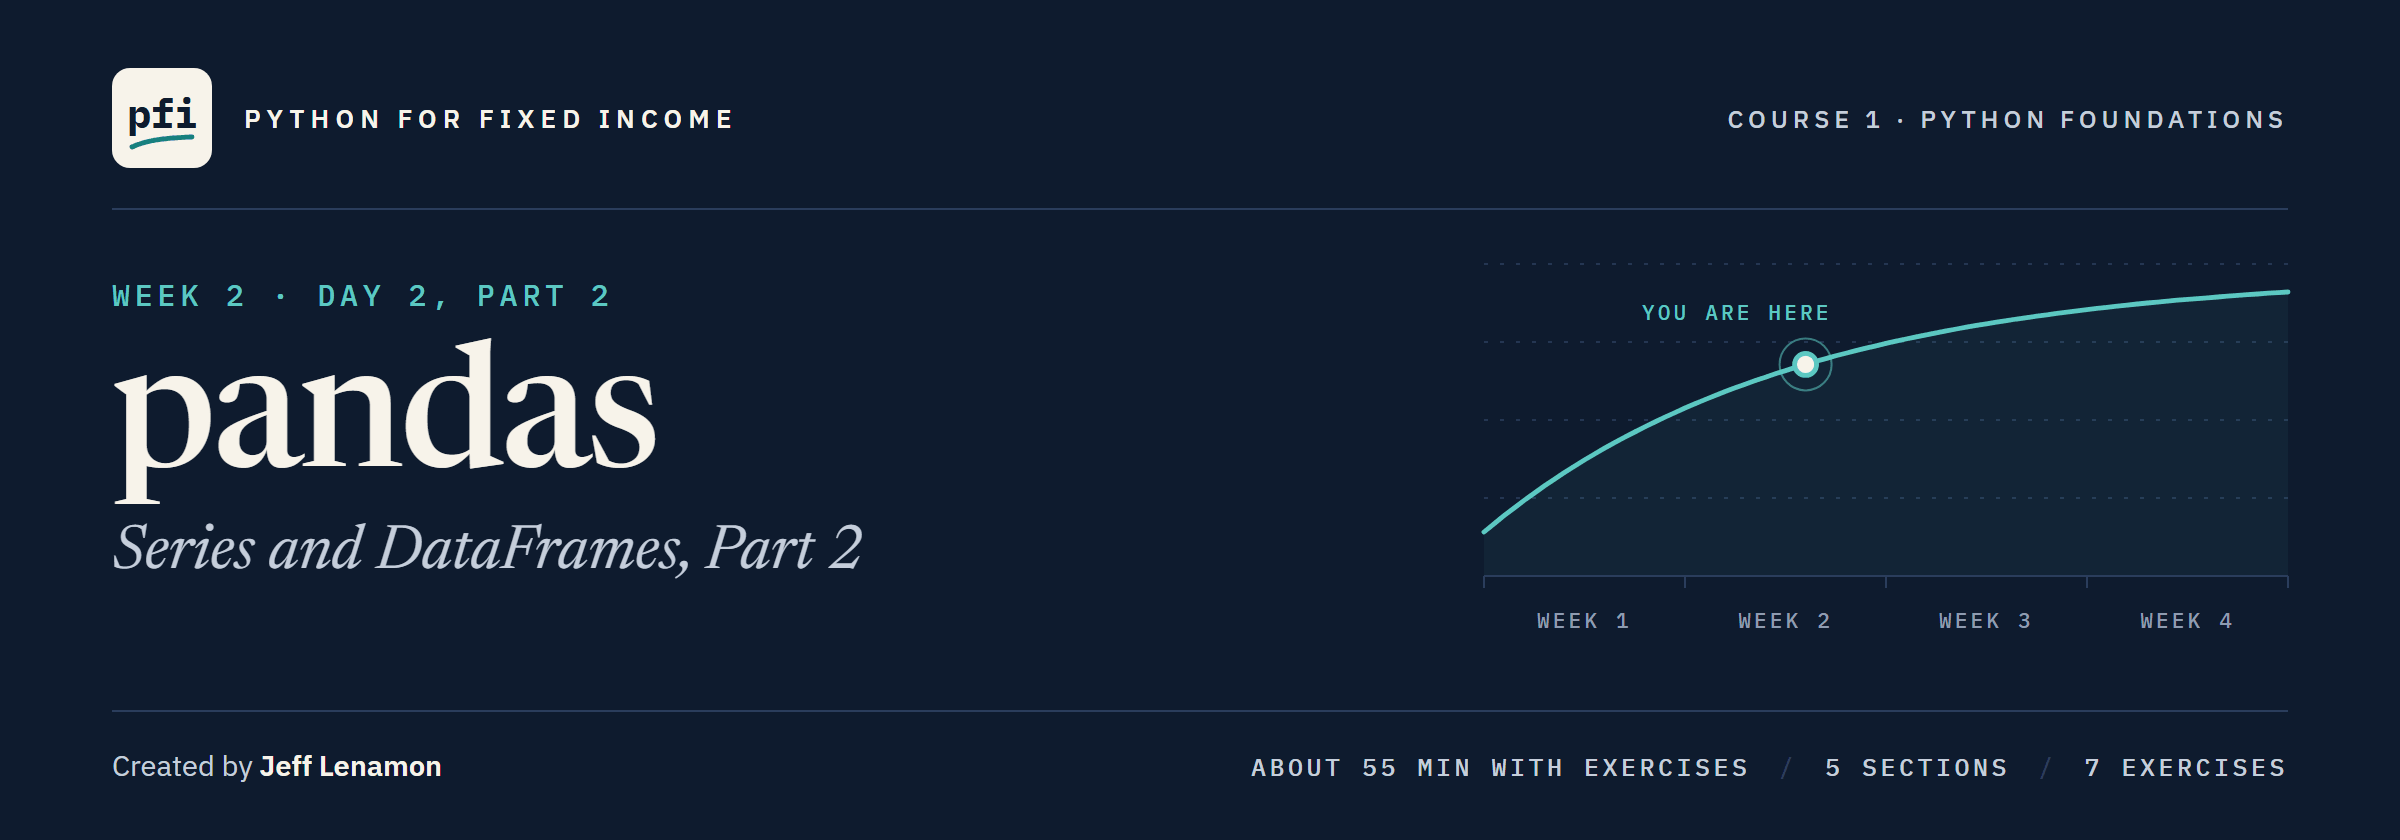

# pandas: Series and DataFrames, Part 2

Week 2, Day 2, Part 2. Summarizing, filtering, sorting, and changing a portfolio of two hundred bonds, and showing a table well.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2_part2/07_part2_pandas_series_and_dataframes.ipynb)

## The Desk Lead's Eleventh Note

> The file is loaded; now make it answer. What is in the book, sector by sector? Which bonds pass a test: Energy, below par, long and cheap? The widest spreads, the biggest positions. Mark BEZL 99039NAC0 at 97.00 on a copy, not our record, and tell me what it costs. Then send the widest spreads in a table I can forward.

### Part 1's Tables in One Cell

A new notebook starts empty.
The issuers are invented.

**Same 200 bonds, same `desk`: every answer checks against Part 1.**

In [1]:
import os

import pandas as pd

# the repo's data folder on your machine; in Colab, GitHub (Part 1, 7.3)
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'
holdings = pd.read_csv(data_path)
# 7.5's table with the CUSIP as row label, and 7.2's four bonds
by_cusip = holdings.set_index('cusip')
desk = pd.DataFrame({
    'Ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'Coupon': [5.25, 6.125, 4.75, 7.5],
    'Maturity': [2033, 2034, 2031, 2032],
    'Price': [98.5, 103.25, 95.0, 101.0],
    'Face': [1500000, 500000, 750000, 250000],
    'Rating': ['BBB', 'BB+', 'A-', 'B+'],
})
print(holdings.shape, desk.shape)

(200, 19) (4, 6)


## Your Route Through Day 2, Part 2

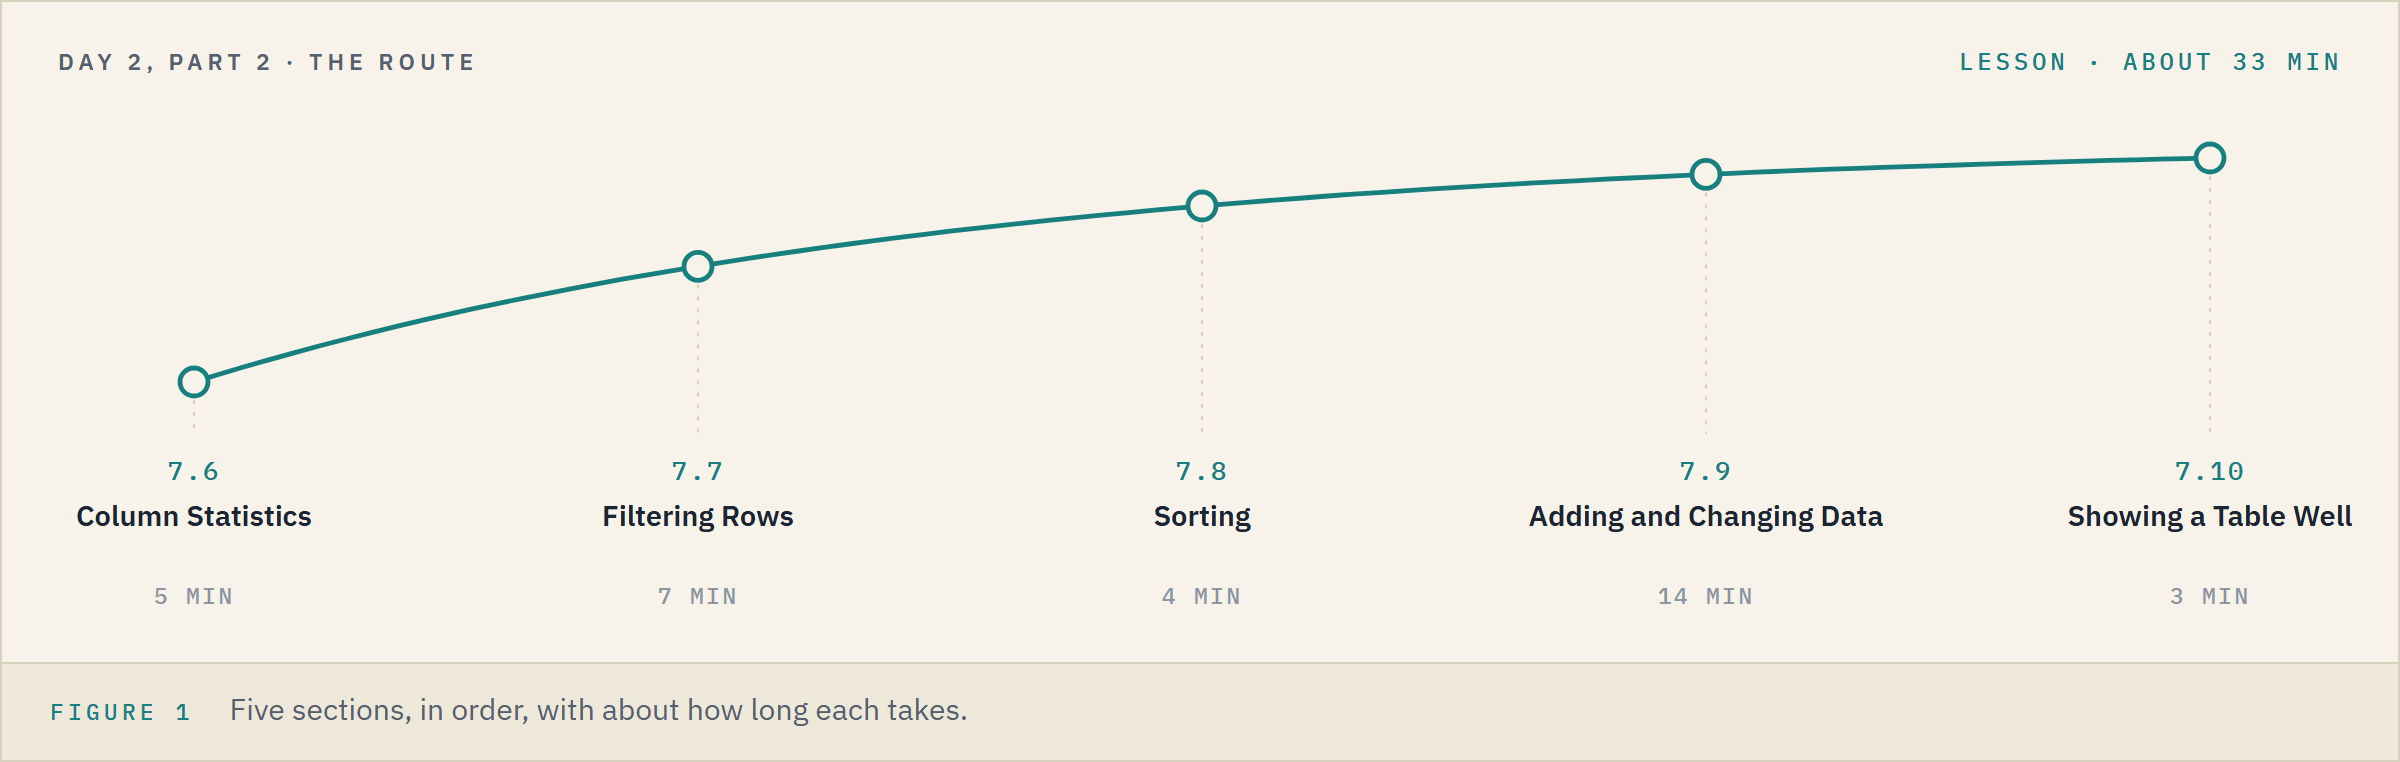

**Time.** About 33 minutes for the lesson, then about 21 for the seven exercises.

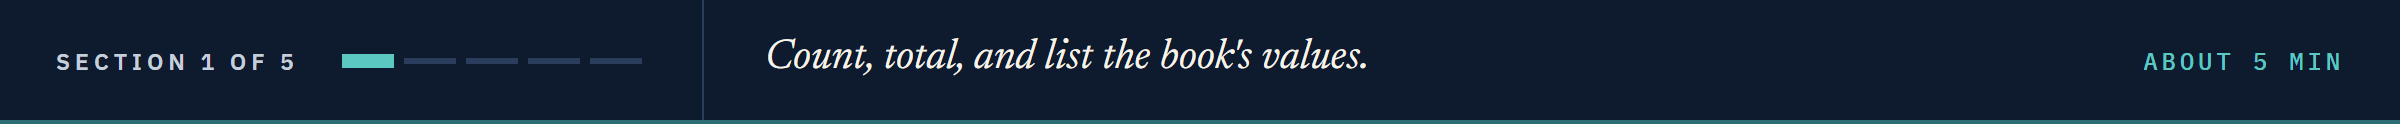

## 7.6 Column Statistics

### Totals, the Middle, and the Ends

Q. What is the book's market value, and how much face does the desk hold?

Q. What are the mean and median spread, and the lowest and highest price?

In [2]:
# sum() adds the column up
print('Market value:', holdings['market_value'].sum())
print('Face held:', holdings['par_held'].sum())
# mean(), median(), min(), max(): describe()'s rows, one at a time (7.4)
print('OAS mean:', holdings['oas'].mean(), 'median:', holdings['oas'].median())
print('Price low:', holdings['price'].min(), 'high:', holdings['price'].max())

Market value: 490819215.0
Face held: 489000000
OAS mean: 185.75 median: 135.5
Price low: 62.045 high: 119.131


Quote the median beside the mean, as 7.4's spreads showed.

### Bonds per Sector

Q. How many bonds does the desk hold in each sector?

Q. Draw the counts.

In [3]:
# value_counts(): how many rows hold each value, largest first; int64 is their type (Day 5)
sector_counts = holdings['sector'].value_counts()
sector_counts

sector
Financials        26
Consumer          26
Materials         26
Telecom           21
Industrials       20
Transportation    20
Health Care       20
Energy            17
Utilities         12
Technology        12
Name: count, dtype: int64

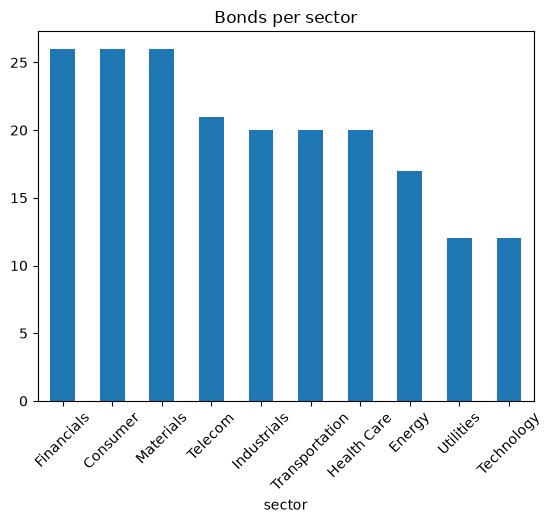

In [4]:
# plot.bar() and rot= as on Day 5; a Series puts its labels along the bottom
chart = sector_counts.plot.bar(rot=45, title='Bonds per sector')

Q. What share of the bonds is in each sector?

In [5]:
# normalize=True: each count as a share of all the rows, a fraction of 1
holdings['sector'].value_counts(normalize=True)

sector
Financials        0.130
Consumer          0.130
Materials         0.130
Telecom           0.105
Industrials       0.100
Transportation    0.100
Health Care       0.100
Energy            0.085
Utilities         0.060
Technology        0.060
Name: proportion, dtype: float64

The shares add up to 1: 26 of 200 is 0.13.

**By count of bonds, not by money: market value by sector is the next notebook's question.**

### Bonds per Rating, and the Most Common

Q. How many bonds carry each rating, and which rating is the most common?

In [6]:
# the same count, on the ratings
print(holdings['rating'].value_counts())
# mode(): the most common value, as a Series, since two values can tie
# iloc[0] takes the first, by position (7.1)
print('Most common rating:', holdings['rating'].mode().iloc[0])

rating
A-      28
BBB-    26
BB+     23
BBB+    21
BB      16
A+      16
BBB     15
A       12
BB-     10
B-       7
B+       6
B        5
AA-      4
CCC+     4
AA       3
AAA      2
AA+      1
CCC      1
Name: count, dtype: int64
Most common rating: A-


With no tie, `mode()` is the top row of `value_counts()`.
The list runs in count order, not credit order.

### Each Value Once, and How Many

Q. Which sectors are there, and does the report date ever change?

Q. How many issuers are there, and is every CUSIP different?

In [7]:
# unique(): each value once, in the order met; tolist() makes it a plain list
print(holdings['sector'].unique().tolist())
print(holdings['as_of_date'].unique().tolist())
# nunique(): how many different values
print('Tickers:', holdings['ticker'].nunique(), 'CUSIPs:', holdings['cusip'].nunique())

['Financials', 'Industrials', 'Transportation', 'Utilities', 'Consumer', 'Materials', 'Technology', 'Telecom', 'Health Care', 'Energy']
['2026-09-30']
Tickers: 115 CUSIPs: 200


One date in every row: a column with one value tells nothing from row to row.
115 tickers for 200 bonds, as BEZL showed in 7.5; 200 CUSIPs, all different, which is why the CUSIP can be the index.

**Excel side by side.**

<table align="left">
<tr><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>holdings['market_value'].sum()</code></td><td align="left"><code>=SUM(S2:S201)</code></td></tr>
<tr><td align="left"><code>holdings['oas'].mean()</code></td><td align="left"><code>=AVERAGE(M2:M201)</code></td></tr>
<tr><td align="left"><code>holdings['oas'].median()</code></td><td align="left"><code>=MEDIAN(M2:M201)</code></td></tr>
<tr><td align="left"><code>holdings['price'].min()</code></td><td align="left"><code>=MIN(I2:I201)</code></td></tr>
<tr><td align="left"><code>holdings['sector'].value_counts()</code></td><td align="left">a pivot table, sector in Rows, a count in Values</td></tr>
<tr><td align="left"><code>value_counts(normalize=True)</code></td><td align="left">the same, Show Values As, % of Grand Total</td></tr>
<tr><td align="left"><code>holdings['sector'].unique()</code></td><td align="left"><code>=UNIQUE(E2:E201)</code> (Excel 2021, Microsoft 365)</td></tr>
<tr><td align="left"><code>holdings['ticker'].nunique()</code></td><td align="left"><code>=COUNTA(UNIQUE(C2:C201))</code> (Excel 2021, Microsoft 365)</td></tr>
</table>
<br clear="left">

**One line per figure, naming the column, not a range. Now pick the rows.**

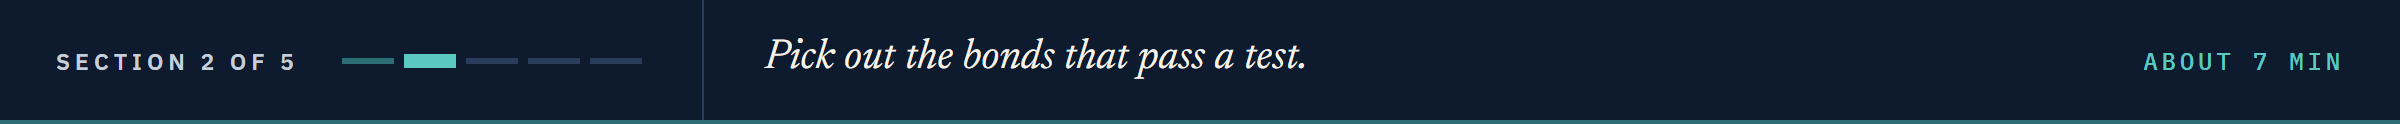

## 7.7 Filtering Rows

### Energy: True or False per Bond

A test on a column picks rows, as NumPy's masks picked bonds (6.5).

Q. Which bonds are in the Energy sector?

In [8]:
# == on a column: a Series of True and False, one per bond
is_energy = holdings['sector'] == 'Energy'
# rows 65 to 68, where the first Energy bonds appear
is_energy.iloc[65:69]

65    False
66    False
67     True
68     True
Name: sector, dtype: bool

### The Mask Picks the Rows

Q. Show the Energy bonds.

In [9]:
# a mask in the square brackets keeps the rows where it is True
energy = holdings[is_energy]
energy[['ticker', 'issuer', 'rating', 'price', 'oas']].head()

,ticker,issuer,rating,price,oas
67,GALN,Galvostrin Resources,BBB+,86.621,99
68,GALN,Galvostrin Resources,BBB+,89.089,88
73,GALY,Galvolvey Resources,A+,93.393,74
82,HESR,Heskentor Resources,BBB-,112.884,155
86,HULR,Hulvimer Pipeline,BBB,93.030,110


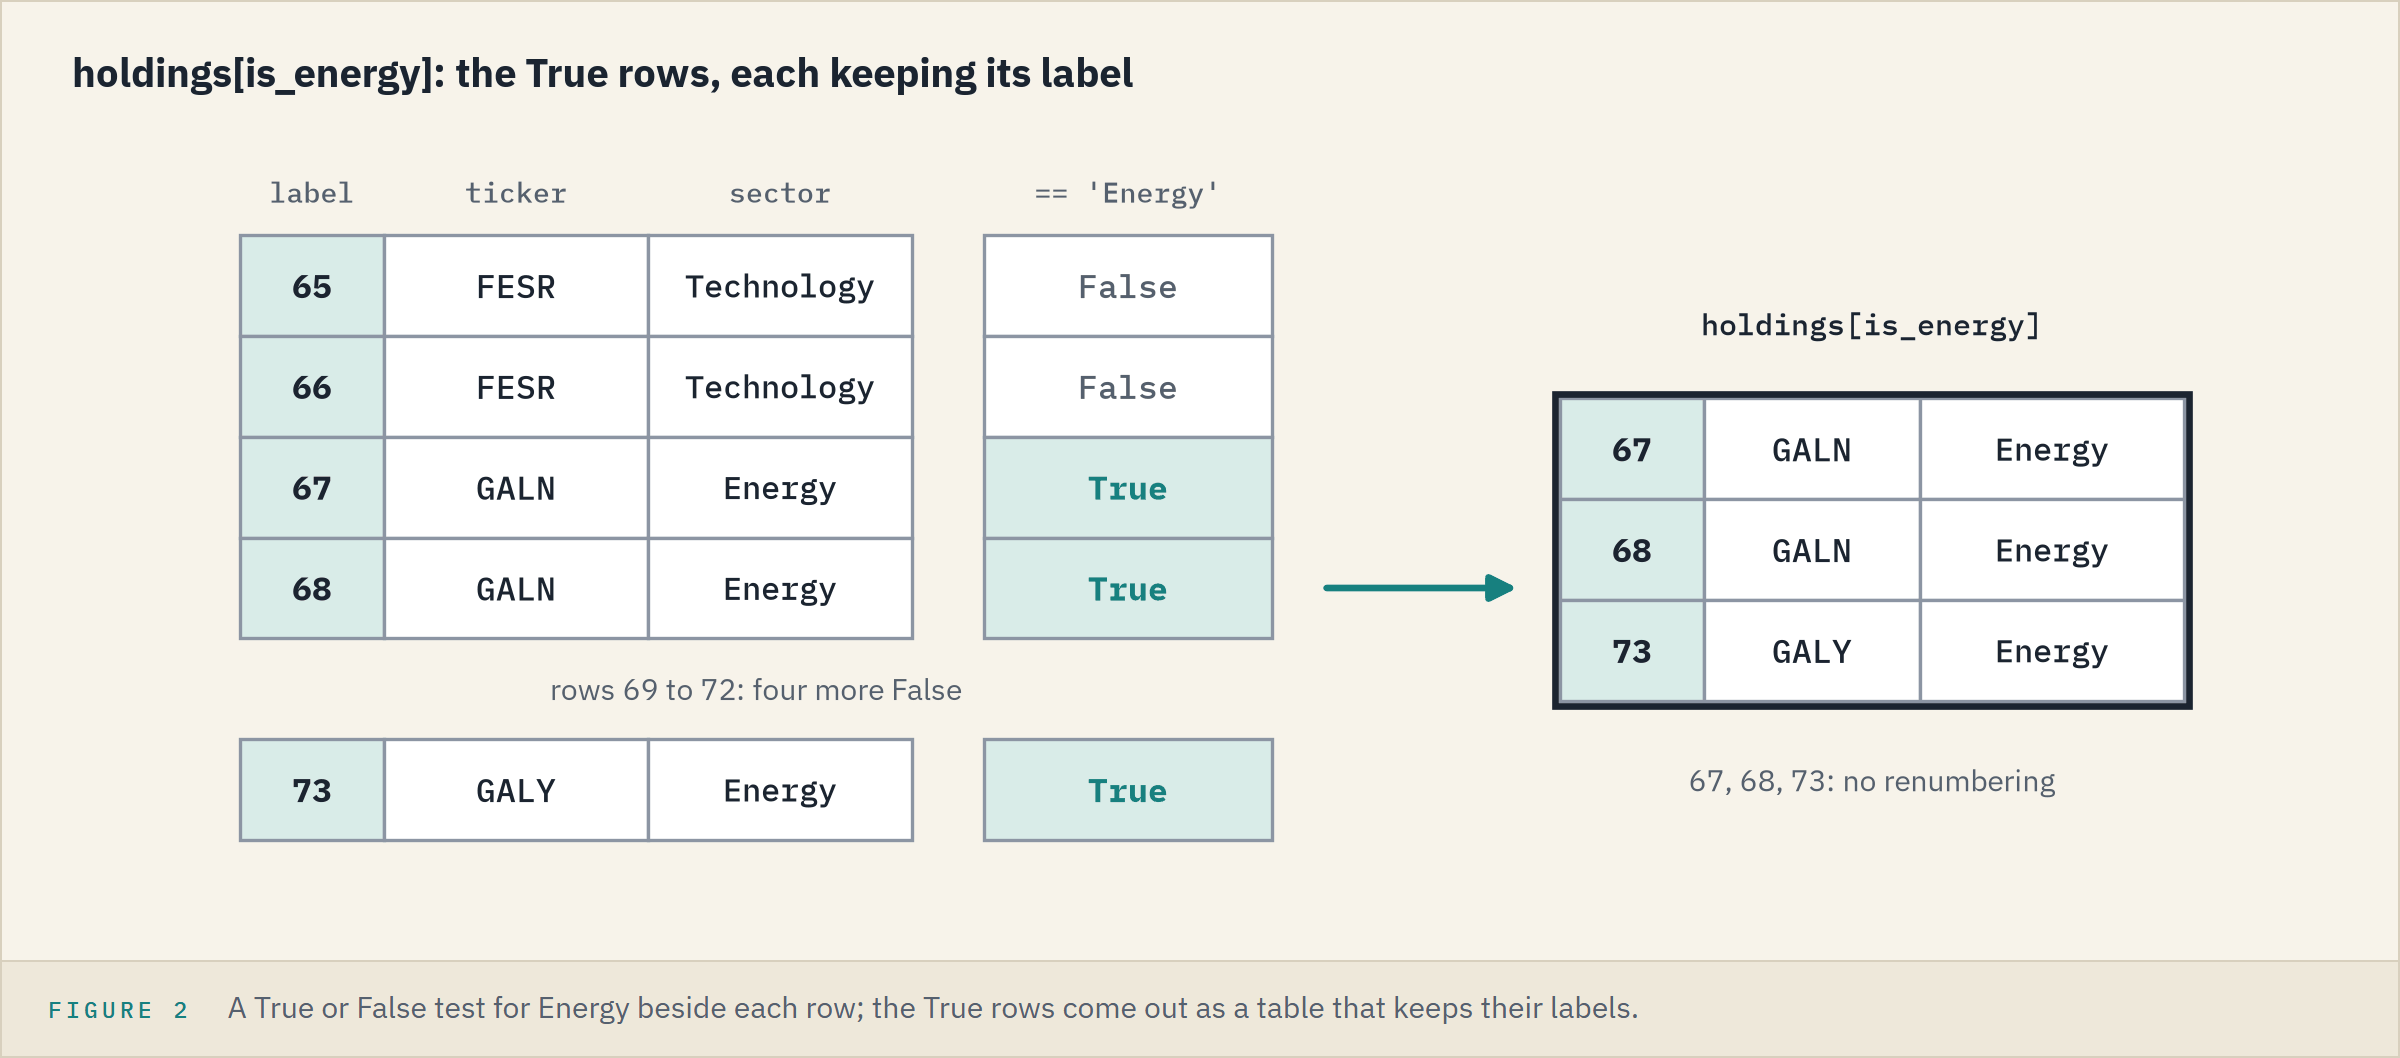

**A filter keeps each row's label.**

### Count and Total With `loc`

Q. How many Energy bonds are there, and what is their market value?

In [10]:
# a mask's sum is a count (NumPy 6.5)
print('Energy bonds:', is_energy.sum())
# loc[mask, column]: the rows where the mask is True, in one column
print('Energy market value:', holdings.loc[is_energy, 'market_value'].sum())

Energy bonds: 17
Energy market value: 38830005.0


### Below Par, Then Spreads Over 500

Q. How many bonds are priced below par?

Q. Show the bonds with a spread over 500 bp.

In [11]:
# the mask written in place
print('Below par:', (holdings['price'] < 100).sum())

Below par: 113


In [12]:
# loc[mask, list of columns]
holdings.loc[holdings['oas'] > 500, ['ticker', 'sector', 'rating', 'price', 'oas']]

,ticker,sector,rating,price,oas
1,BEZH,Industrials,B,97.556,535
17,CLDB,Consumer,B,62.045,1446
18,CLDB,Consumer,B,95.248,520
65,FESR,Technology,CCC+,87.116,1551
66,FESR,Technology,CCC+,87.473,614
72,GALX,Materials,B-,87.457,679
110,NEVN,Utilities,B-,96.616,720
111,NEVN,Utilities,B-,94.053,719
131,PRAN,Financials,CCC+,100.010,707
132,PRAN,Financials,CCC+,89.407,871


Every one is rated B+ or lower.

### Both Tests, or Either

Q. Which bonds have a duration over 10 and a price under 90?

Q. Which have a price under 80 or a spread over 1,000 bp?

In [13]:
# & keeps a row where both tests are True; a bracket round each test, as in NumPy 6.5
long_and_low = (holdings['duration'] > 10) & (holdings['price'] < 90)
print('Count:', long_and_low.sum())
holdings.loc[long_and_low, ['ticker', 'coupon', 'maturity', 'price', 'duration']]

Count: 6


,ticker,coupon,maturity,price,duration
36,DNMR,5.250,2047-06-05,89.056,11.764
84,HLVF,7.625,2053-06-08,88.366,10.218
105,MORX,6.125,2055-12-21,85.722,12.139
117,NEVX,3.875,2048-01-06,73.873,12.898
150,SYLX,3.625,2055-09-03,76.903,16.042
184,WYXA,6.750,2056-02-23,86.884,11.558


In [14]:
# | keeps a row where either test is True
low_or_wide = (holdings['price'] < 80) | (holdings['oas'] > 1000)
print('Count:', low_or_wide.sum())
holdings.loc[low_or_wide, ['ticker', 'rating', 'price', 'oas']]

Count: 4


,ticker,rating,price,oas
17,CLDB,B,62.045,1446
65,FESR,CCC+,87.116,1551
117,NEVX,BBB-,73.873,153
150,SYLX,A+,76.903,59


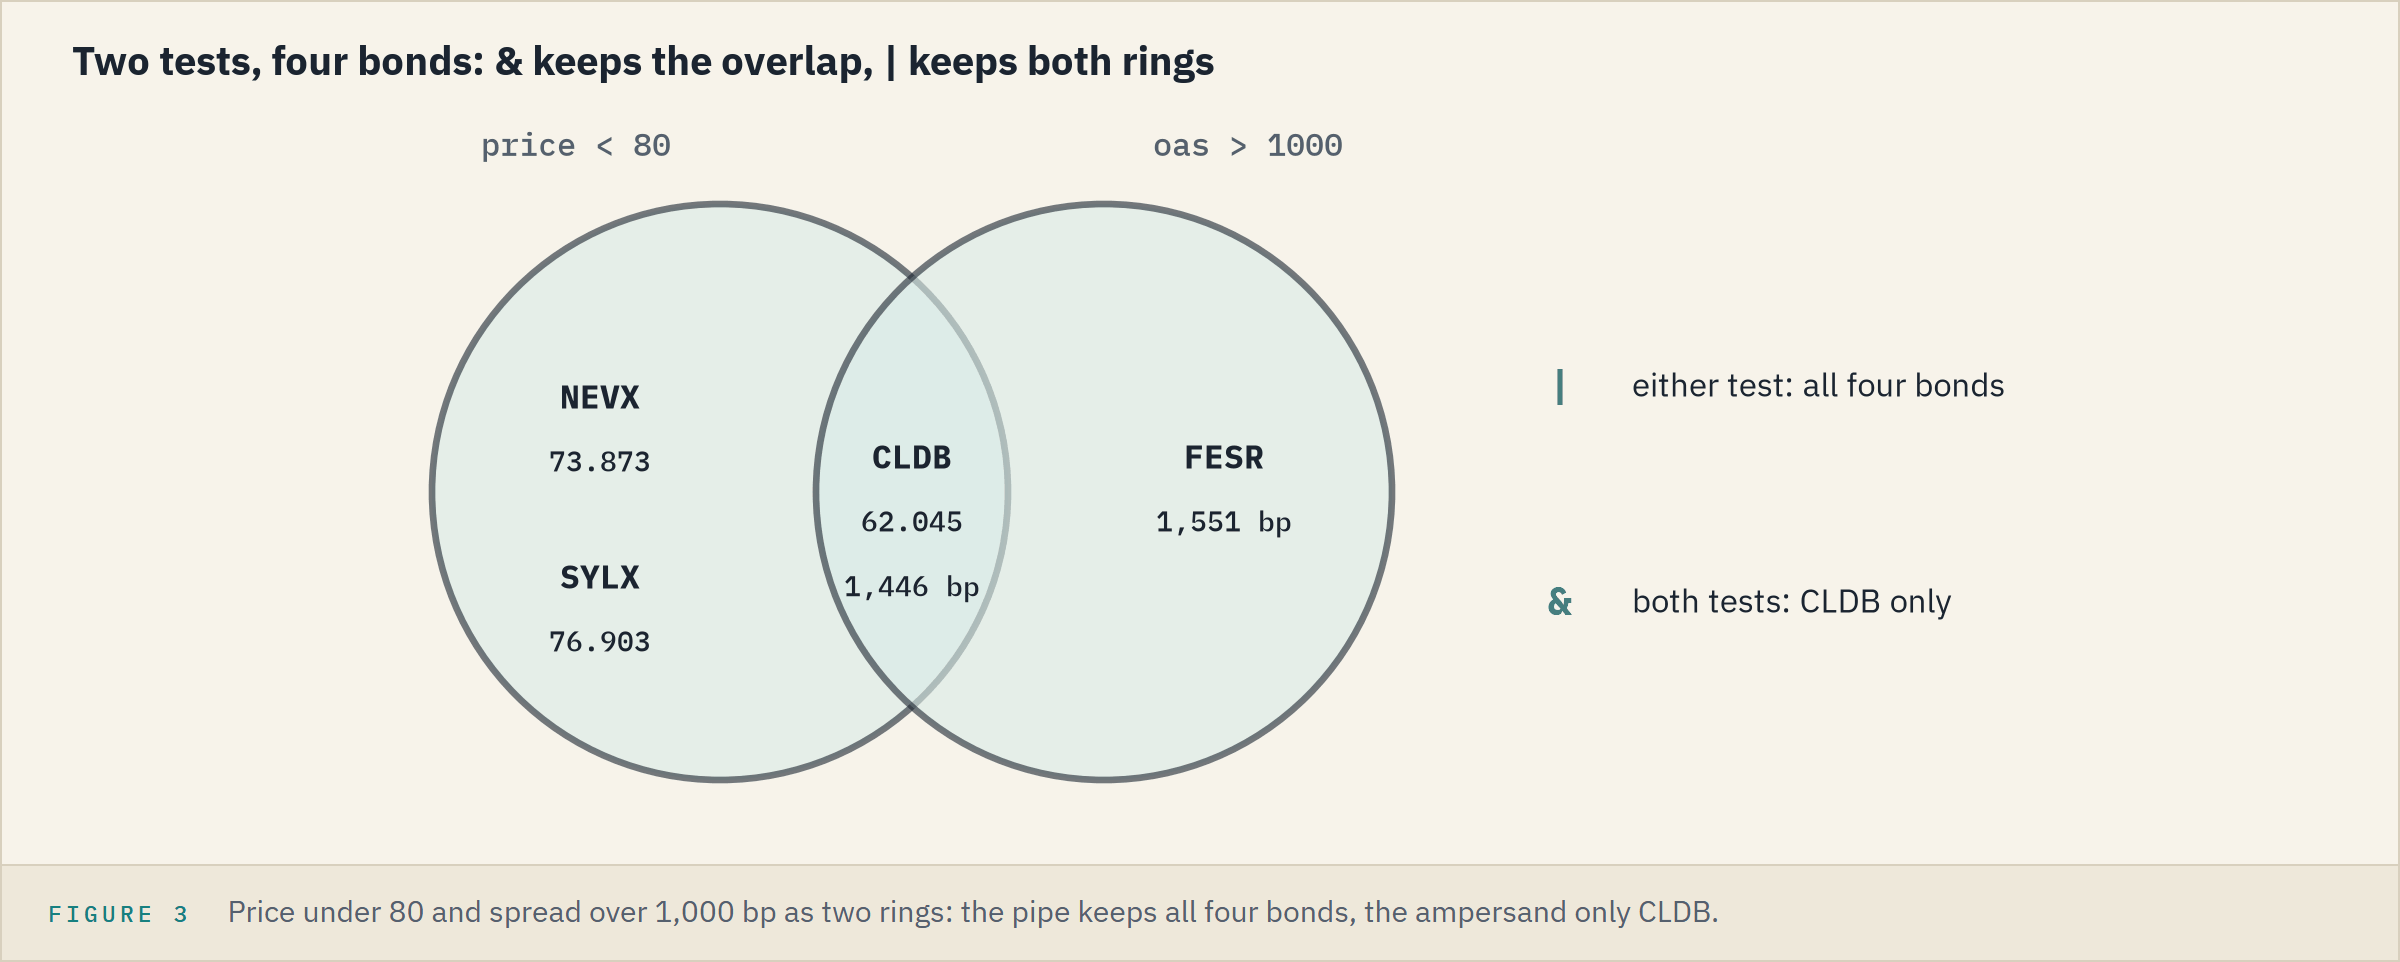

The word `and` fails here as in NumPy 6.5: "The truth value of a Series is ambiguous".

**`&` narrows, `|` widens, and a swap raises no error: check the count.**

### One of Several Ratings

Q. How many bonds are rated single-A, and what is their average spread?

In [15]:
# isin(): True where the value is one of those in the list
single_a = holdings['rating'].isin(['A+', 'A', 'A-'])
print('Single-A bonds:', single_a.sum())
print('Average OAS:', round(holdings.loc[single_a, 'oas'].mean(), 2))

Single-A bonds: 56
Average OAS: 79.41


79.41 bp against 185.75 for the whole book.

**Excel side by side.** Sector in E, rating in F, price in I, OAS in M, duration in N, market value in S.

<table align="left">
<tr><th align="left">Question</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Show the Energy bonds</td><td align="left"><code>holdings[is_energy]</code></td><td align="left">AutoFilter on the sector column</td></tr>
<tr><td align="left">Count them</td><td align="left"><code>is_energy.sum()</code></td><td align="left"><code>=COUNTIF(E:E, "Energy")</code></td></tr>
<tr><td align="left">Their market value</td><td align="left"><code>holdings.loc[is_energy, 'market_value'].sum()</code></td><td align="left"><code>=SUMIF(E:E, "Energy", S:S)</code></td></tr>
<tr><td align="left">Average OAS of one rating</td><td align="left"><code>holdings.loc[holdings['rating'] == 'A', 'oas'].mean()</code></td><td align="left"><code>=AVERAGEIF(F:F, "A", M:M)</code></td></tr>
<tr><td align="left">Both tests</td><td align="left"><code>long_and_low.sum()</code></td><td align="left"><code>=COUNTIFS(N:N, "&gt;10", I:I, "&lt;90")</code></td></tr>
<tr><td align="left">One of several ratings</td><td align="left"><code>single_a.sum()</code></td><td align="left"><code>=SUM(COUNTIF(F:F, {"A+","A","A-"}))</code></td></tr>
</table>
<br clear="left">

**The filter is in writing: read, reviewed, rerun. Now put the book in order.**

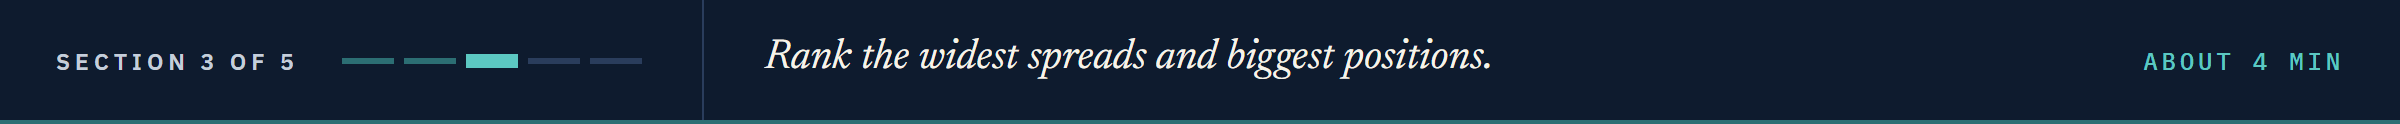

## 7.8 Sorting

### The Widest Spreads

Q. Which bonds have the widest spreads?

Q. Draw the ten widest.

In [16]:
# sort_values(): the rows in order of a column; ascending=False puts the largest first
widest = holdings.sort_values('oas', ascending=False)
widest[['ticker', 'sector', 'rating', 'price', 'oas']].head()

,ticker,sector,rating,price,oas
65,FESR,Technology,CCC+,87.116,1551
17,CLDB,Consumer,B,62.045,1446
132,PRAN,Financials,CCC+,89.407,871
110,NEVN,Utilities,B-,96.616,720
111,NEVN,Utilities,B-,94.053,719


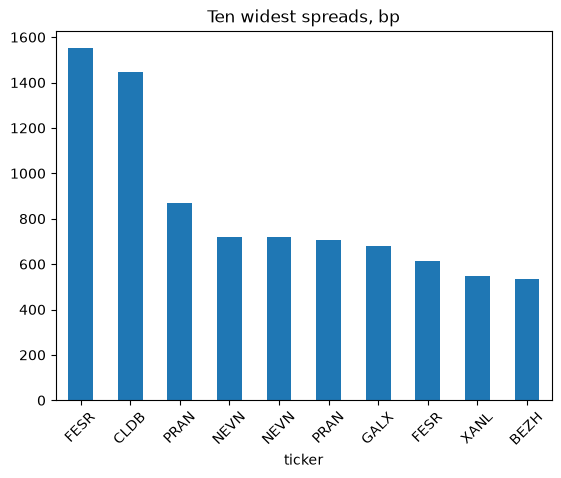

In [17]:
# x= names the column along the bottom, y= the bar heights; legend=False as on Day 5
chart = widest.head(10).plot.bar(x='ticker', y='oas', rot=45, legend=False,
                                 title='Ten widest spreads, bp')

Each label moved with its row, and `holdings` keeps its order (7.5).
FESR, PRAN, and NEVN each appear twice: a ticker is not a bond.

### Largest Positions, Lowest Prices

Q. Which five positions are the largest by market value?

Q. Which three bonds have the lowest prices?

In [18]:
# nlargest(n, column): sort, then head, in one step
holdings.nlargest(5, 'market_value')[['ticker', 'par_held', 'price', 'market_value']]

,ticker,par_held,price,market_value
0,BEZE,5000000,106.727,5435500.0
59,FESA,5000000,106.471,5422700.0
103,LORN,4750000,109.248,5287462.5
194,ZARL,5000000,101.481,5253950.0
104,LORX,5000000,104.801,5241650.0


In [19]:
# nsmallest(): the same from the other end
holdings.nsmallest(3, 'price')[['ticker', 'coupon', 'maturity', 'price']]

,ticker,coupon,maturity,price
17,CLDB,9.500,2034-12-06,62.045
117,NEVX,3.875,2048-01-06,73.873
150,SYLX,3.625,2055-09-03,76.903


LORN holds less face than the four 5,000,000 positions and ranks third on its price.

### Ratings in Order

**Predict 1**

Q. The desk sorts the holdings by rating. Where does AAA land?

A) First.
B) Last.
C) Somewhere in the middle.

In [20]:
# sort by rating, then list each rating once, in the sorted order
by_rating = holdings.sort_values('rating')
print(by_rating['rating'].unique().tolist())

['A', 'A+', 'A-', 'AA', 'AA+', 'AA-', 'AAA', 'B', 'B+', 'B-', 'BB', 'BB+', 'BB-', 'BBB', 'BBB+', 'BBB-', 'CCC', 'CCC+']


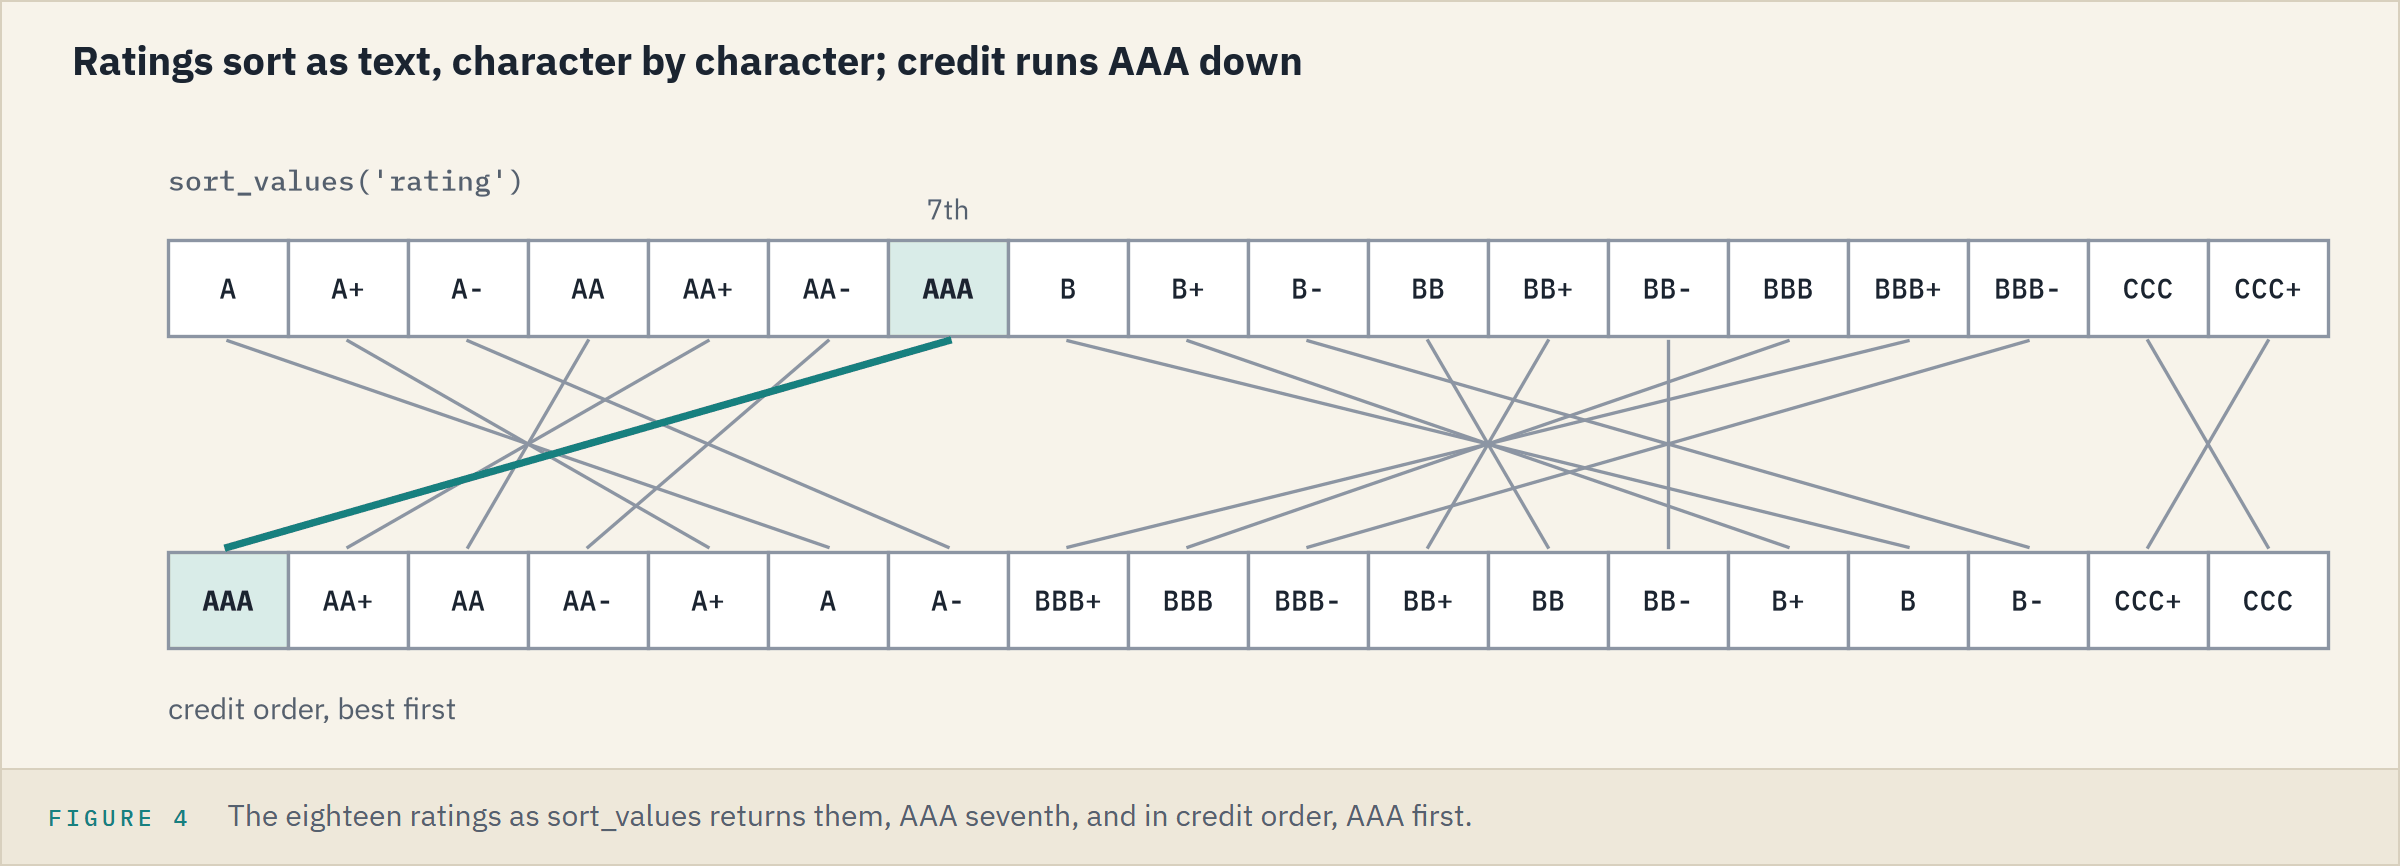

C: seventh.
Text sorts character by character, and `+` and `-` come before letters, so A, A+, and A- all come before AA.

**Excel side by side.** Data, Sort reorders the sheet itself; `=SORT(A2:S201, 13, -1)` in Excel 2021 and Microsoft 365 spills a sorted copy, as `sort_values()` hands one back.
`=LARGE(S2:S201, 1)` and `=SMALL(I2:I201, 1)` give one value each; `nlargest()` and `nsmallest()` give whole rows.

**Credit order needs a number per rating, like week 1's score. Now change the table, on a copy.**

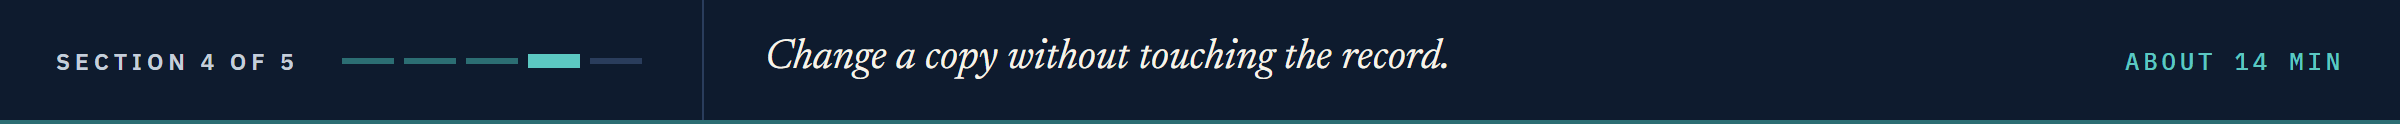

## 7.9 Adding and Changing Data

### Coupon Income per Position

Q. Add each position's annual coupon income: face held times coupon, divided by 100.

In [21]:
# a new name on the left of = creates the column, at the right-hand end
holdings['coupon_income'] = holdings['par_held'] * holdings['coupon'] / 100
print('Total annual coupon income:', holdings['coupon_income'].sum())
holdings[['ticker', 'coupon', 'par_held', 'coupon_income']].head(3)

Total annual coupon income: 28864375.0


,ticker,coupon,par_held,coupon_income
0,BEZE,7.000,5000000,350000.0
1,BEZH,8.125,250000,20312.5
2,BEZL,5.125,1500000,76875.0


### Each Position's Weight

Q. Add each position's weight, in percent of the book's market value. Which three are the largest?

In [22]:
# each market value over the total, in percent
holdings['weight_pct'] = holdings['market_value'] / holdings['market_value'].sum() * 100
print('Sum of the weights:', round(holdings['weight_pct'].sum(), 6))
holdings.nlargest(3, 'weight_pct')[['ticker', 'market_value', 'weight_pct']]

Sum of the weights: 100.0


,ticker,market_value,weight_pct
0,BEZE,5435500.0,1.107434
59,FESA,5422700.0,1.104826
103,LORN,5287462.5,1.077273


Weights adding up to 100 is the check on any weight column.
BEZE is about 1.11 percent, against 0.5 for an equal split.

### A Column From a List

Q. Add week 1's rating scores to the four-bond table, as a new column.

In [23]:
# a list becomes a column, in row order
desk_scores = desk.copy()
desk_scores['Score'] = [9, 11, 7, 14]
print(desk_scores[['Ticker', 'Rating', 'Score']])

  Ticker Rating  Score
0   QVNE    BBB      9
1   DNMR    BB+     11
2   PLWK     A-      7
3   HLVF     B+     14


**Predict 2**

Q. The next cell hands the same table three scores for its four bonds. What happens?

A) The fourth row gets `NaN`.
B) The list starts again, so the fourth row gets 9.
C) An error.

In [24]:
# three scores for four bonds
desk_scores['Score'] = [9, 11, 7]

ValueError: Length of values (3) does not match length of index (4)

C: pandas will not guess which bond lacks a score (NumPy 6.3).
A Series would line up by label and leave `NaN` (7.1).

**A list has no labels: its length must match the rows.**

### The Note's Mark, on a Copy

Q. On a copy, mark BEZL 5.125% 2030, CUSIP 99039NAC0, at 97.00; the file has 98.73.

In [25]:
# copy(): a separate table, so the what-if cannot reach the desk's record
what_if = by_cusip.copy()
# loc[row label, column name] on the left of = sets that one value
what_if.loc['99039NAC0', 'price'] = 97.0
print('What-if:', what_if.loc['99039NAC0', 'price'])
print('Record:', by_cusip.loc['99039NAC0', 'price'])

What-if: 97.0
Record: 98.73


Without `.copy()`, `what_if = by_cusip` gives one table two names (Day 3), and 97 lands on the record.
Set a value with one `loc[row, column]`.
Older code writes two bracket pairs, `what_if['price']['99039NAC0'] = 97.0`: depending on the pandas version, that changes the table, warns, or does nothing.

### Market Value Does Not Follow

Q. Has BEZL's market value followed? Recompute the column: how much does the book move?

In [26]:
# still the file's figure
print(what_if.loc['99039NAC0', 'market_value'])
# rerun the line: face held times (price plus accrued), divided by 100
what_if['market_value'] = what_if['par_held'] * (what_if['price'] + what_if['accrued']) / 100
change = what_if['market_value'].sum() - by_cusip['market_value'].sum()
print('Change in market value:', round(change, 2))

1505940.0
Change in market value: -25950.0


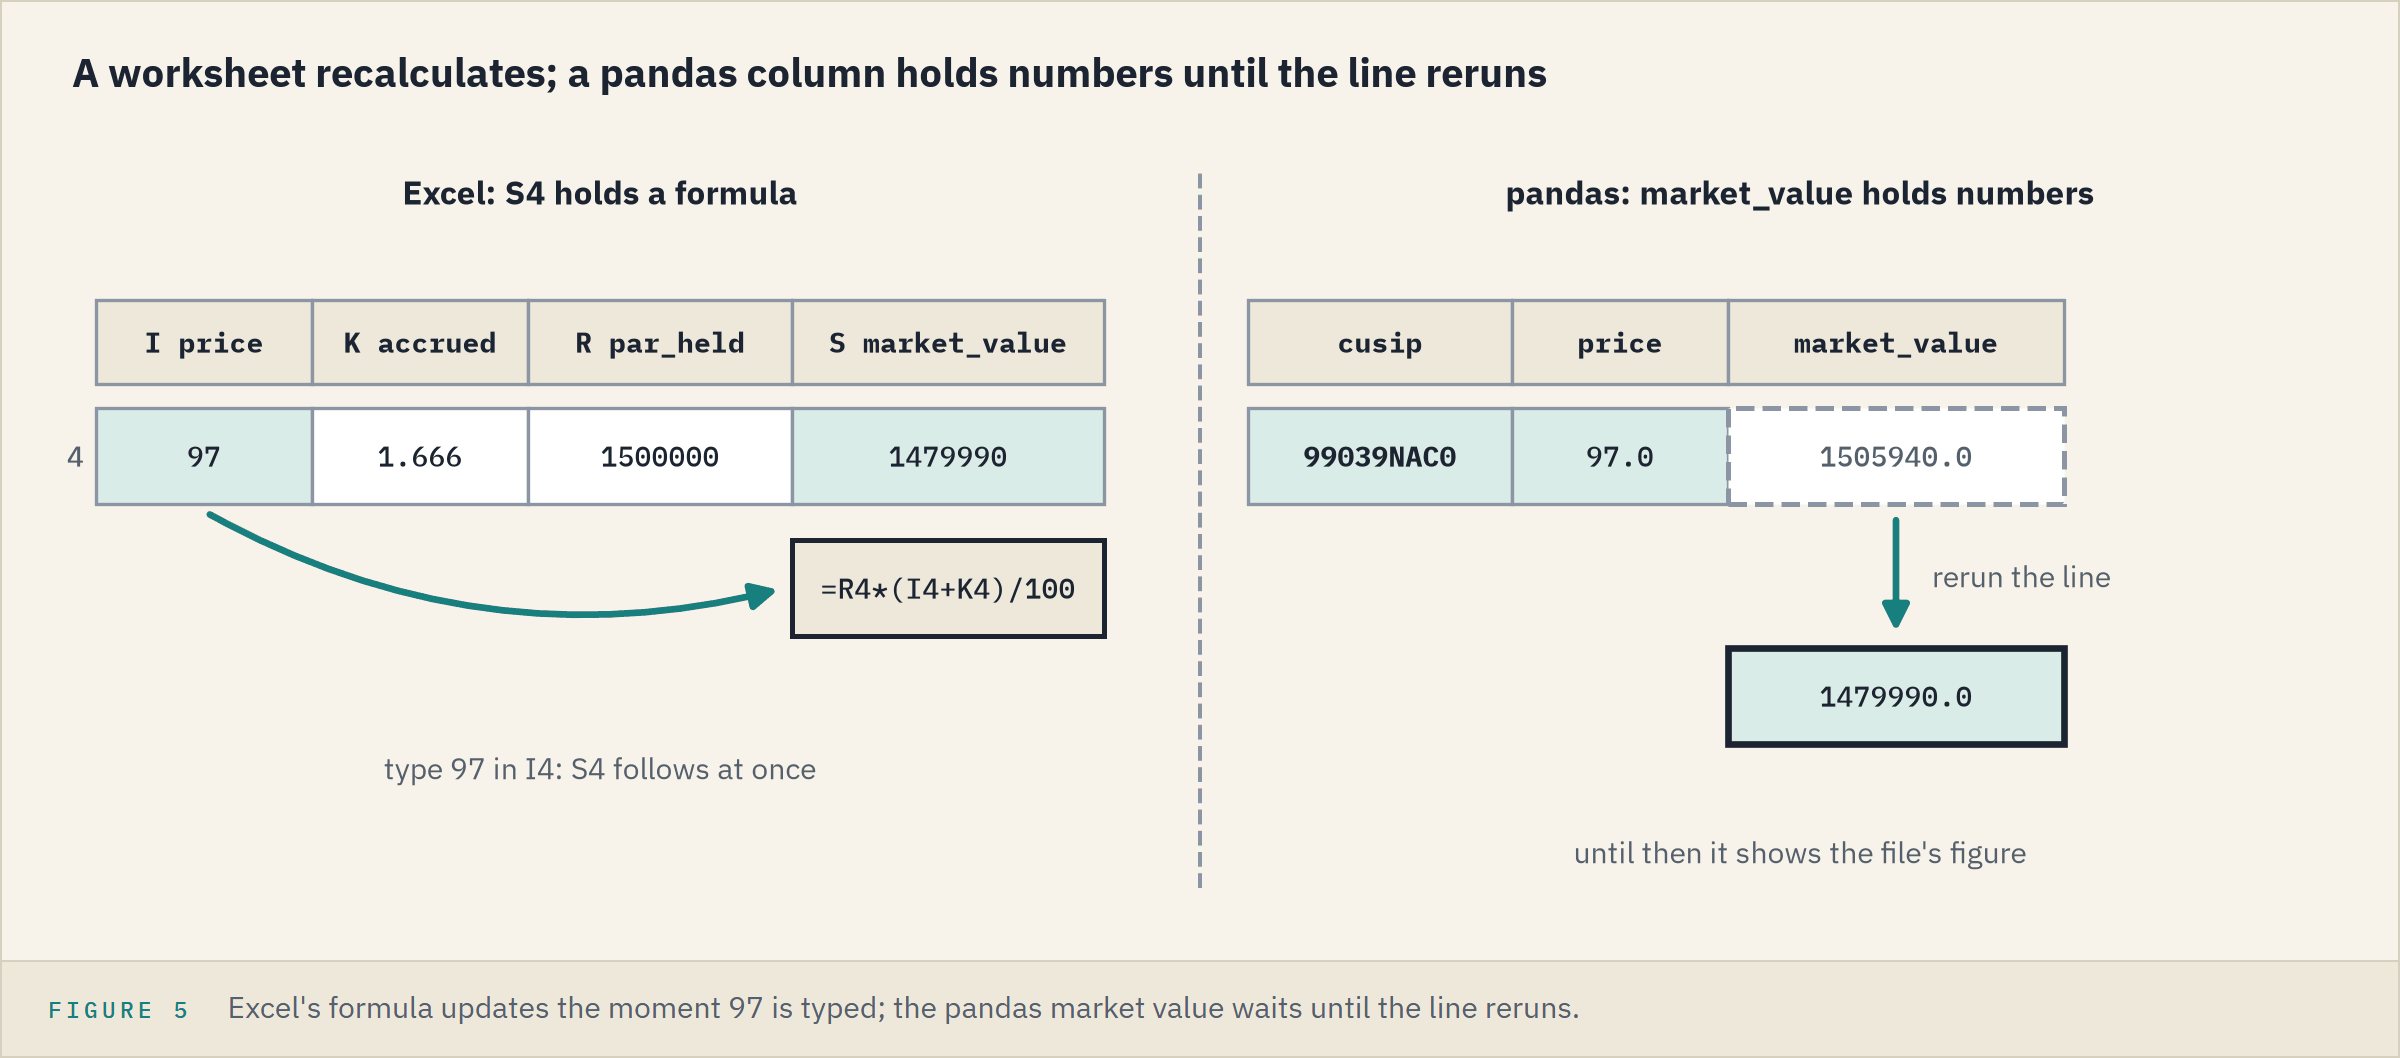

1,500,000 of face marked 1.73 points lower: 1,500,000 times 1.73, divided by 100.

**A column holds values, not formulas: change an input, rerun the line.**

### Every Bond That Passes a Test

Q. The pricing team will confirm every bond priced under 80. In a copy, label those 'Confirm' and the rest 'OK'.

In [27]:
# a copy; one value on the right fills every row, as in NumPy 6.5
marks = holdings.copy()
marks['price_check'] = 'OK'
# loc[mask, column] = value sets that column in the rows where the mask is True
marks.loc[marks['price'] < 80, 'price_check'] = 'Confirm'
marks.loc[marks['price'] < 80, ['ticker', 'price', 'price_check']]

,ticker,price,price_check
17,CLDB,62.045,Confirm
117,NEVX,73.873,Confirm
150,SYLX,76.903,Confirm


The single `loc` from above, a mask in place of the label: the right form of the two-bracket line.
The label asks for a price check; it says nothing about the bond.

### Filter, Then Copy

Q. Take the 17 Energy bonds as a table of their own, every price 2 points lower. Do the holdings move?

In [28]:
# a filtered table about to change: copy it, and say so in the code
energy_what_if = holdings[is_energy].copy()
energy_what_if['price'] = energy_what_if['price'] - 2
print(f"What-if average price: {energy_what_if['price'].mean():.3f}")
print(f"Record average price:  {holdings.loc[is_energy, 'price'].mean():.3f}")

What-if average price: 95.407
Record average price:  97.407


In pandas 3 a filter hands back a table of its own, so `holdings` is safe even without `.copy()`.
Older pandas, which Colab may run, warns `SettingWithCopyWarning` without it.
With `.copy()` every version agrees: filter, then copy, before changing anything.

### One Value by Position

Q. In a copy of the holdings, change the first bond's price by position.

In [29]:
# iloc[row, column] on the left of = sets one value by position; column 8 is price
positional = holdings.copy()
positional.iloc[0, 8] = 100.0
print('Copy:', positional.loc[0, 'price'], 'Record:', holdings.loc[0, 'price'])

Copy: 100.0 Record: 106.727


`loc` when you know the bond; `iloc` when you know only where it sits.

### Rename, Then Drop Two Columns

Q. In the what-if, rename `oas` to `oas_bp` and `par_held` to `face_held`.

In [30]:
# rename() takes a dictionary, old name: new name, and returns a new table: assign it back
what_if = what_if.rename(columns={'oas': 'oas_bp', 'par_held': 'face_held'})
what_if[['ticker', 'oas_bp', 'face_held']].head(2)

,ticker,oas_bp,face_held
cusip,,,
99080CAE8,BEZE,147,5000000
99049XAE2,BEZH,535,250000


**Predict 3**

Q. `what_if` is a copy of `by_cusip`, made from `holdings` in the first cell; `holdings` has gained two columns since. How many columns does `what_if` have before and after the two date columns go?

A) 21, then 19.
B) 18, then 16.
C) 20, then 18.

In [31]:
# shape: rows, then columns, before and after the drop
print('Before:', what_if.shape)
# drop(columns=...) returns a table without those columns
what_if = what_if.drop(columns=['as_of_date', 'price_date'])
print('After:', what_if.shape)

Before: (200, 18)
After: (200, 16)


B: `by_cusip` was made before the new columns and does not follow `holdings`; the CUSIP is its index, not a column (Part 1's Predict 6).

### Drop a Bond by Its CUSIP

Q. Take BEZE 7% 2032, CUSIP 99080CAE8, out of the what-if.

In [32]:
# drop(index=...) returns a table without the row with that label
what_if = what_if.drop(index='99080CAE8')
print('What-if rows:', what_if.shape[0], 'Record rows:', holdings.shape[0])

What-if rows: 199 Record rows: 200


### Older Code: `axis` and `inplace`

Q. Older tutorials drop columns and rows with `axis`. What does it do?

In [33]:
# a copy of the four-bond table, to drop from
older = desk.copy()
# axis=1: a column, as drop(columns='Rating')
older = older.drop('Rating', axis=1)
# axis=0: a row, here the one labelled 1, DNMR
older = older.drop(1, axis=0)
print(older)

  Ticker  Coupon  Maturity  Price     Face
0   QVNE    5.25      2033   98.5  1500000
2   PLWK    4.75      2031   95.0   750000
3   HLVF    7.50      2032  101.0   250000


**Predict 4**

Q. Older tutorials also write `inplace=True`. What does `result` hold after the next cell?

A) A new table without the Face column.
B) `None`.

In [34]:
# drop Face with inplace=True, and keep what drop() hands back
result = older.drop(columns=['Face'], inplace=True)
print('Returned:', result)
print('Columns now:', older.columns.tolist())

Returned: None
Columns now: ['Ticker', 'Coupon', 'Maturity', 'Price']


B: `inplace=True` changed `older` itself and handed back `None`.
Leave it out and assign the result: `older = older.drop(...)`.

### Renumber the Rows

Q. With DNMR gone, the labels run 0, 2, 3. Renumber them from 0.

In [35]:
# reset_index(drop=True): number the rows from 0, throwing the old labels away
print(older.reset_index(drop=True))
# without drop=True the old labels stay, as a column named index
print(older.reset_index())

  Ticker  Coupon  Maturity  Price
0   QVNE    5.25      2033   98.5
1   PLWK    4.75      2031   95.0
2   HLVF    7.50      2032  101.0
   index Ticker  Coupon  Maturity  Price
0      0   QVNE    5.25      2033   98.5
1      2   PLWK    4.75      2031   95.0
2      3   HLVF    7.50      2032  101.0


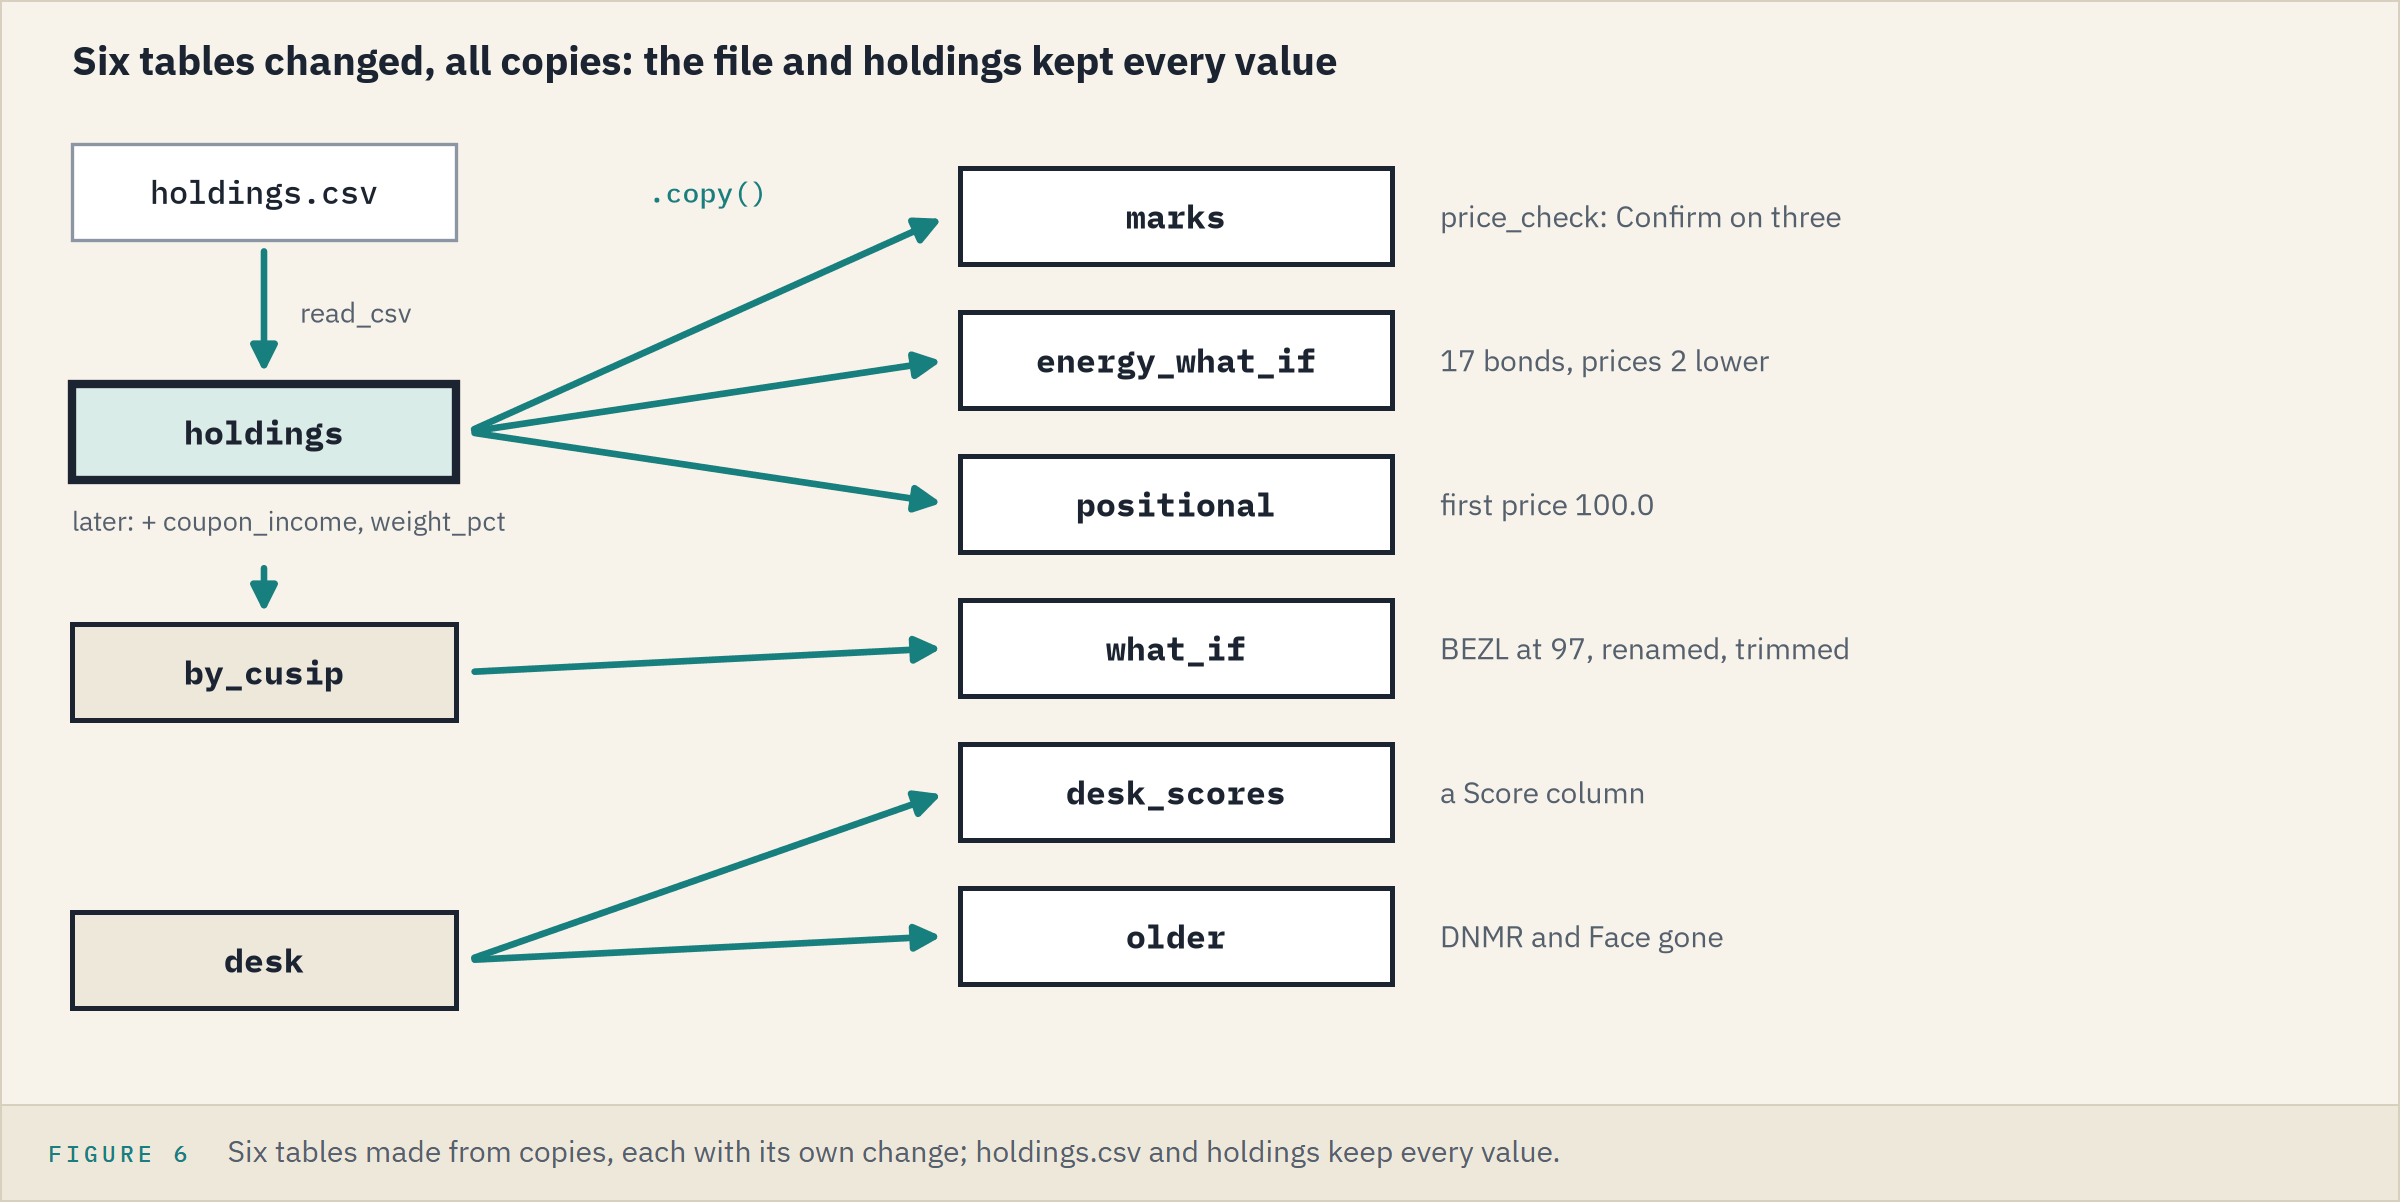

**Excel side by side.**

<table align="left">
<tr><th align="left">Step</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Add a column</td><td align="left"><code>holdings['par_held'] * holdings['coupon'] / 100</code></td><td align="left"><code>=R2*G2/100</code>, filled down</td></tr>
<tr><td align="left">Weight</td><td align="left"><code>holdings['market_value'] / holdings['market_value'].sum() * 100</code></td><td align="left"><code>=S2/SUM(S:S)*100</code>, filled down</td></tr>
<tr><td align="left">Work on a copy</td><td align="left"><code>by_cusip.copy()</code></td><td align="left">Move or Copy, Create a copy</td></tr>
<tr><td align="left">Overwrite one value</td><td align="left"><code>what_if.loc['99039NAC0', 'price'] = 97.0</code></td><td align="left">type over the cell</td></tr>
<tr><td align="left">Set the rows that pass a test</td><td align="left"><code>marks.loc[marks['price'] &lt; 80, 'price_check'] = 'Confirm'</code></td><td align="left"><code>=IF(I2&lt;80, "Confirm", "OK")</code>, filled down</td></tr>
<tr><td align="left">Copy filtered rows</td><td align="left"><code>holdings[is_energy].copy()</code></td><td align="left">copy what an AutoFilter shows: only those rows are copied</td></tr>
<tr><td align="left">Rename, remove</td><td align="left"><code>rename()</code>, <code>drop()</code></td><td align="left">retype the header; Delete</td></tr>
</table>
<br clear="left">

**Every what-if landed on a copy. Now show it well.**

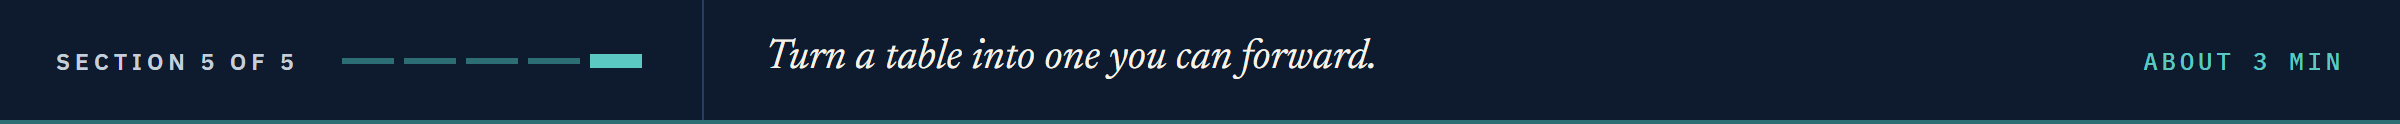

## 7.10 Showing a Table Well

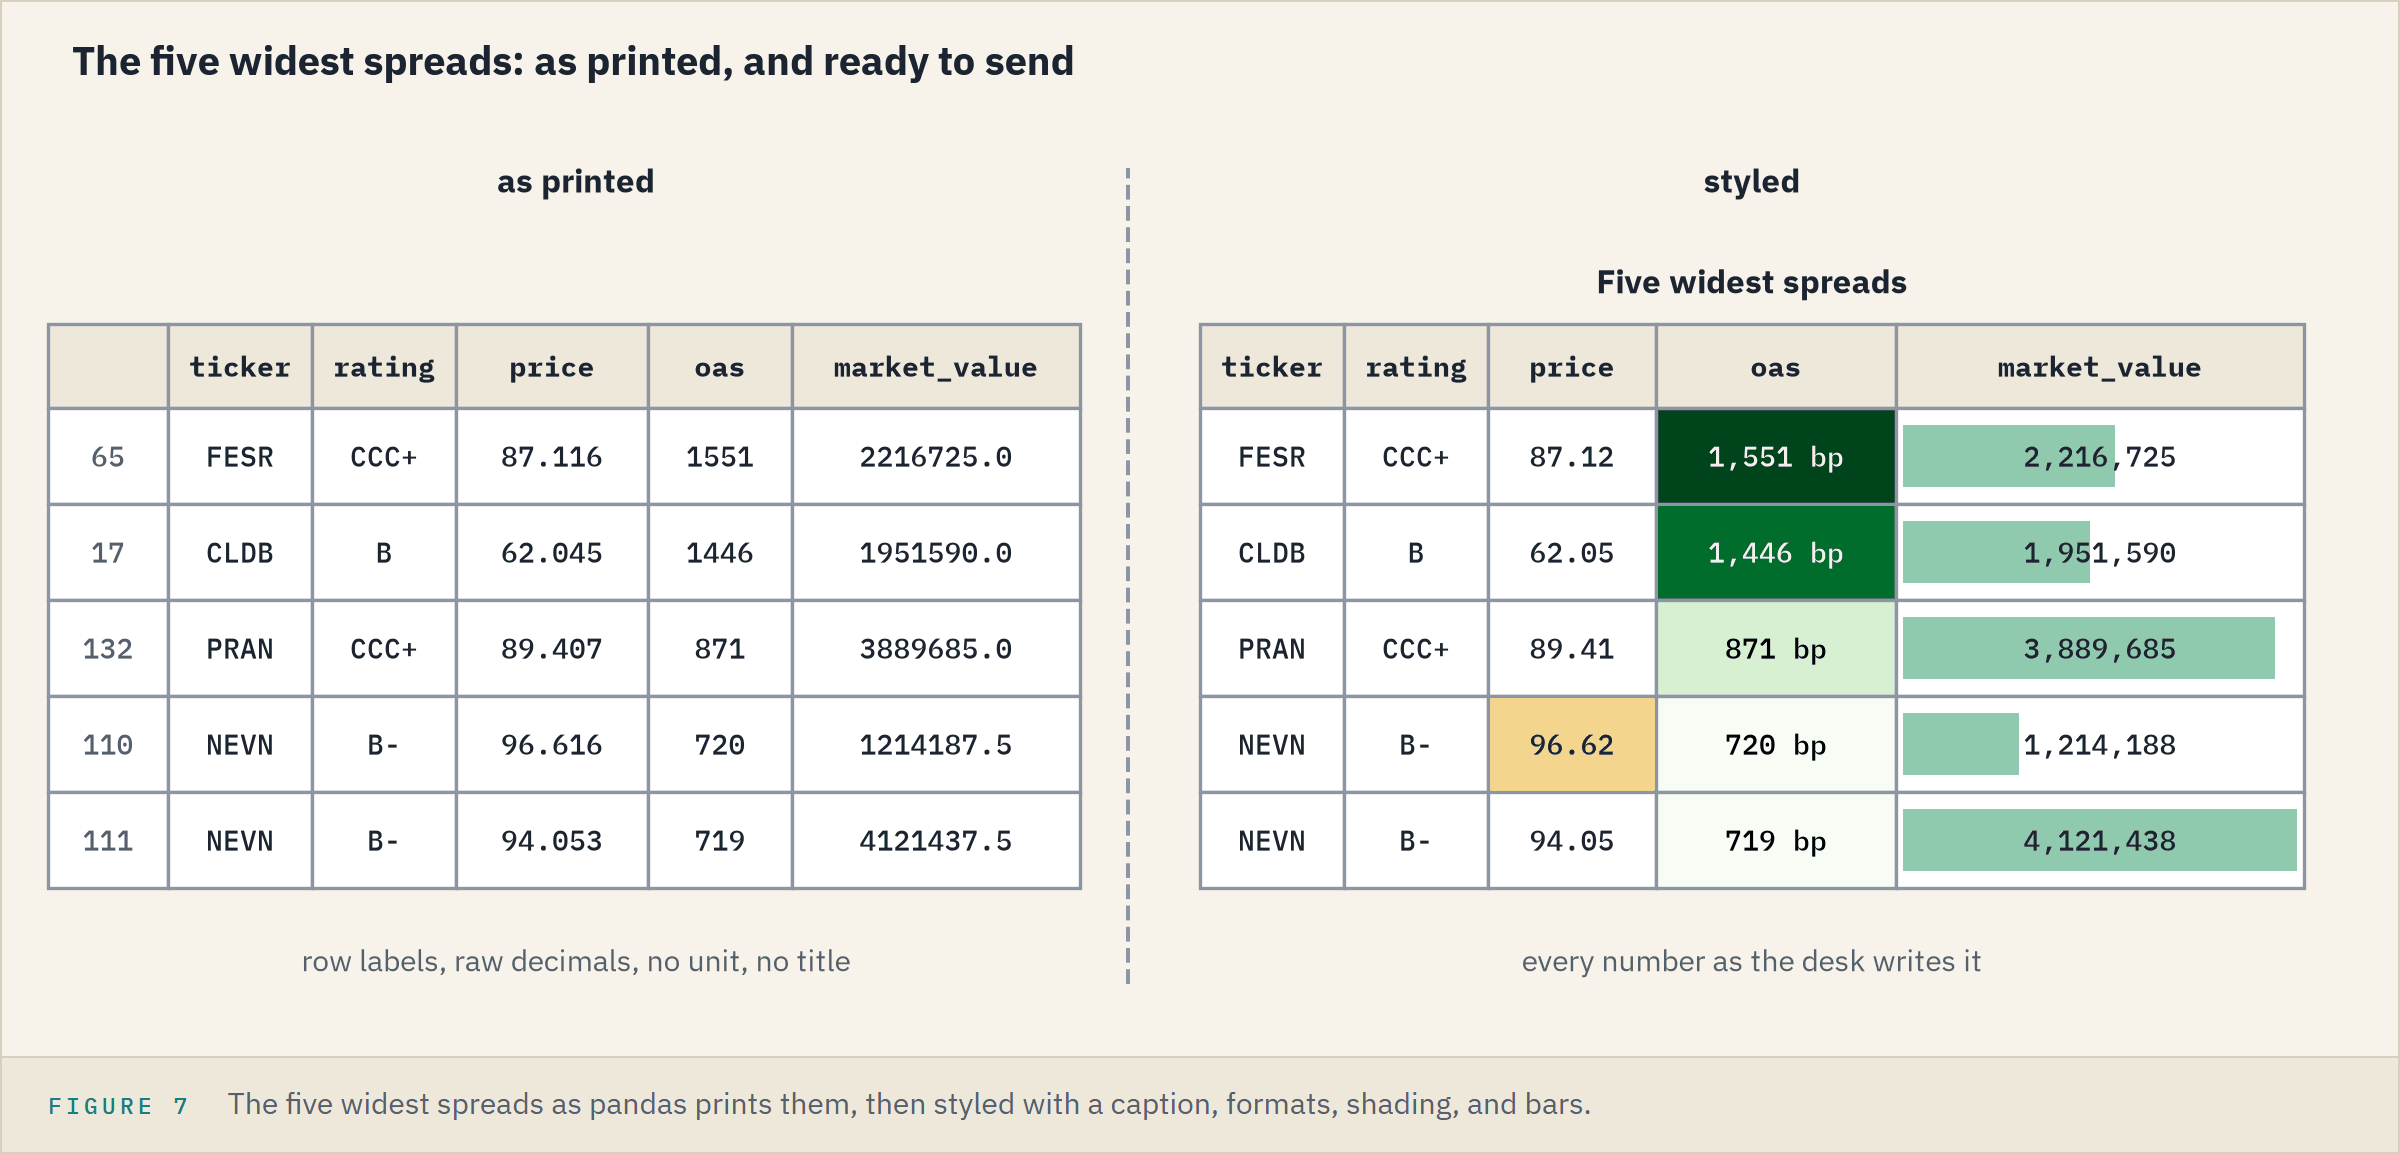

`.style` formats the display, as Excel's Format Cells and Conditional Formatting do.

### Format, Caption, No Row Numbers

Q. Show the five widest: prices to two decimals, spreads in bp, market values with commas, a title.

In [36]:
# nlargest() as in 7.8: the five widest, five columns
widest5 = holdings.nlargest(5, 'oas')[['ticker', 'rating', 'price', 'oas', 'market_value']]
# .style.format(): how each column shows; set_caption(): a title
# hide(axis='index'): no row labels; round brackets let one statement run over several lines
(widest5.style.format({'price': '{:.2f}', 'oas': '{:,.0f} bp', 'market_value': '{:,.0f}'})
    .set_caption('Five widest spreads')
    .hide(axis='index'))

ticker,rating,price,oas,market_value
FESR,CCC+,87.12,"1,551 bp","2,216,725"
CLDB,B,62.05,"1,446 bp","1,951,590"
PRAN,CCC+,89.41,871 bp,"3,889,685"
NEVN,B-,96.62,720 bp,"1,214,188"
NEVN,B-,94.05,719 bp,"4,121,438"


The codes are week 1's f-string codes (Day 1): `.0` means no decimals.
Display only: `widest5` keeps every digit, as a cell formatted to two decimals still holds 87.116; `round()` changes the number itself.

### Shade, Mark, and Bar

Q. Shade the spreads, mark the highest price, and put a bar in each market value cell.

In [37]:
# subset= picks the columns a step works on; cmap= a colour map, 'Greens' a ready-made run
# '#f4d58d' and '#8fc9ae' are colours written as codes, the way a web page writes them
(widest5.style.format({'price': '{:.2f}', 'oas': '{:,.0f} bp', 'market_value': '{:,.0f}'})
    .background_gradient(subset=['oas'], cmap='Greens')
    .highlight_max(subset=['price'], color='#f4d58d')
    .bar(subset=['market_value'], color='#8fc9ae')
    .set_caption('Five widest spreads')
    .hide(axis='index'))

ticker,rating,price,oas,market_value
FESR,CCC+,87.12,"1,551 bp","2,216,725"
CLDB,B,62.05,"1,446 bp","1,951,590"
PRAN,CCC+,89.41,871 bp,"3,889,685"
NEVN,B-,96.62,720 bp,"1,214,188"
NEVN,B-,94.05,719 bp,"4,121,438"


**Excel side by side.**

<table align="left">
<tr><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>.style.format({'price': '{:.2f}'})</code></td><td align="left">Format Cells, Number, 2 decimal places</td></tr>
<tr><td align="left"><code>.style.format({'oas': '{:,.0f} bp'})</code></td><td align="left">Format Cells, Custom, <code>#,##0" bp"</code></td></tr>
<tr><td align="left"><code>.background_gradient(cmap='Greens')</code></td><td align="left">Conditional Formatting, Color Scales</td></tr>
<tr><td align="left"><code>.highlight_max()</code></td><td align="left">Conditional Formatting, Top/Bottom Rules, Top 10 Items, set to 1</td></tr>
<tr><td align="left"><code>.bar()</code></td><td align="left">Conditional Formatting, Data Bars</td></tr>
<tr><td align="left"><code>.set_caption('...')</code></td><td align="left">a title in the row above the table</td></tr>
<tr><td align="left"><code>.hide(axis='index')</code></td><td align="left">View, untick Headings: row numbers and column letters both go</td></tr>
</table>
<br clear="left">

**For another reader: formatted numbers, a caption, shading only where it helps.**

## You Can Now

By the end of this notebook, you can:

* Total, average, and count a column, with the median beside the mean.
* Count each group and its share with `value_counts()`.
* Filter the book on one test or several, and count or total what passes.
* Rank it: widest spreads, largest positions.
* Add a calculated column, and run a what-if on a copy.
* Set every row that passes a test with `loc[mask, column] = value`, copying a filtered table first.
* Drop columns and rows, renumber the index, and show a table with formats, shading, and bars.

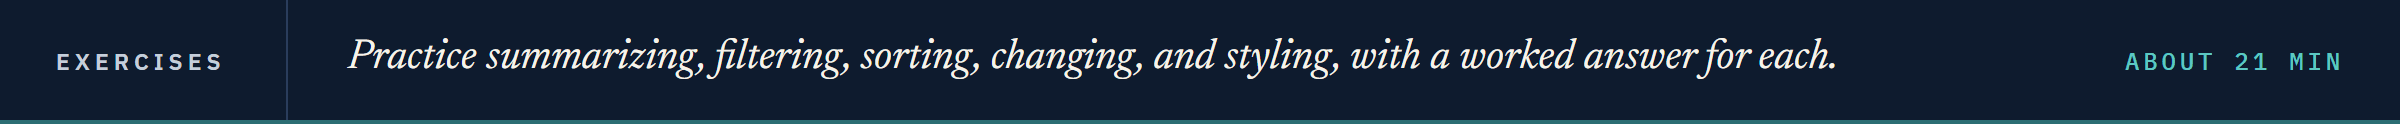

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the holdings file; the issuers are invented.

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it loads a fresh copy of the holdings and defines `check`, which marks your answers.

In [38]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text;
    # isinstance(expected, list) is True when expected is a list
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# a fresh copy of the holdings. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

holdings = pd.read_csv(data_path)
print(holdings.shape)

(200, 19)


### Exercise 1

Q. How many bonds does the desk hold in the Materials sector, and how much face do they add up to? Store the answers in **ex1_count** and **ex1_face**.

In [39]:
ex1_count = ...
ex1_face = ...

In [40]:
check('Exercise 1 count', ex1_count, 26)
check('Exercise 1 face', ex1_face, 70500000)

Exercise 1 count: not attempted yet
Exercise 1 face: not attempted yet


### Exercise 2

Q. How many bonds are rated BBB+ and have a duration above 7? What is the average OAS of those bonds, rounded to two decimal places? Store the answers in **ex2_count** and **ex2_avg_oas**.

In [41]:
ex2_count = ...
ex2_avg_oas = ...

In [42]:
check('Exercise 2 count', ex2_count, 12)
check('Exercise 2 average OAS', ex2_avg_oas, 114.08)

Exercise 2 count: not attempted yet
Exercise 2 average OAS: not attempted yet


### Exercise 3

Q. Use `isin()` to keep the bonds in the Health Care and Technology sectors, and count them. Among those bonds, find the three with the largest DTS and list their CUSIPs, largest first. Store the answers in **ex3_count** and, as a list, in **ex3_cusips**.

In [43]:
ex3_count = ...
ex3_cusips = ...

In [44]:
check('Exercise 3 count', ex3_count, 32)
check('Exercise 3 CUSIPs', ex3_cusips, ['99069RAD2', '99014OAC7', '99016QAE6'])

Exercise 3 count: not attempted yet
Exercise 3 CUSIPs: not attempted yet


### Exercise 4

The desk asks for two figures that are not in the file.

Q. Add a column named `current_yield`: the coupon divided by the price, in percent. Then make a table indexed by CUSIP and use `loc` to look up the current yield of the bond with CUSIP 99071TAG7, rounded to two decimal places. Store it in **ex4_current_yield**.

Q. What percent of the portfolio's market value is in the Utilities sector, rounded to two decimal places? Store it in **ex4_utilities_weight**.

In [45]:
ex4_current_yield = ...
ex4_utilities_weight = ...

In [46]:
check('Exercise 4 current yield', ex4_current_yield, 4.1)
check('Exercise 4 Utilities weight', ex4_utilities_weight, 5.91)

Exercise 4 current yield: not attempted yet
Exercise 4 Utilities weight: not attempted yet


### Exercise 5

Exercise 4 found one sector's weight; a function holds the steps once and answers it for any sector, on any file.

Q. Write a function `sector_weight(table, sector)` that takes a holdings table and the name of a sector, and returns the percent of the table's market value that is in that sector, rounded to two decimal places. The first line and the docstring are given. Replace the `...` in the body with your code, and end it with `return`. Then call it for the Energy sector and store the answer in **ex5_energy_weight**.

In [47]:
def sector_weight(table, sector):
    """
    Take a holdings table and the name of a sector,
    and return the percent of the table's market value in that sector,
    rounded to two decimal places.
    """
    ...


ex5_energy_weight = ...

In [48]:
# the first check calls your function on the holdings
check('Exercise 5 Utilities weight', sector_weight(holdings, 'Utilities'), 5.91)
check('Exercise 5 Energy weight', ex5_energy_weight, 7.91)

Exercise 5 Utilities weight: not attempted yet
Exercise 5 Energy weight: not attempted yet


### Exercise 6

Q. What share of the 200 bonds, as a fraction of 1, is in the Utilities sector? Store it in **ex6_utilities_share**. Then take the five bonds with the widest spreads, keep only the `ticker`, `rating`, and `oas` columns, and renumber the rows from 0 with `reset_index(drop=True)`. Store the table in **ex6_widest**. Finally show that table as a styled table, with the spread formatted as `{:,.0f} bp` and a caption of your choice, and store the styled table in **ex6_styled**.

In [49]:
ex6_utilities_share = ...
ex6_widest = ...
ex6_styled = ...

In [50]:
check('Exercise 6 Utilities share', ex6_utilities_share, 0.06)
check('Exercise 6 widest tickers', ... if ex6_widest is ... else ex6_widest['ticker'].tolist(), ['FESR', 'CLDB', 'PRAN', 'NEVN', 'NEVN'])
check('Exercise 6 renumbered index', ... if ex6_widest is ... else ex6_widest.index.tolist(), [0, 1, 2, 3, 4])
# type(x).__name__ is the name of x's type as text: a styled table's is 'Styler'
check('Exercise 6 styled table', ... if ex6_styled is ... else type(ex6_styled).__name__, 'Styler')

Exercise 6 Utilities share: not attempted yet
Exercise 6 widest tickers: not attempted yet
Exercise 6 renumbered index: not attempted yet
Exercise 6 styled table: not attempted yet


### Exercise 7: AI check

You ask an AI assistant for the number of bonds that are rated BBB+ and have a duration above 7, and for the average OAS of those bonds.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What numbers do you expect? You worked both out yourself in Exercise 2. Then run the code. Does it agree with you?

Q. Find the bug and fix the code in the cell below, so that **ex7_count** and **ex7_avg_oas** hold the right answers.

In [51]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# select the BBB+ bonds with a duration above 7
ai_filter = (holdings['rating'] == 'BBB+') | (holdings['duration'] > 7)

ex7_count = ai_filter.sum()
ex7_avg_oas = round(holdings.loc[ai_filter, 'oas'].mean(), 2)

print(f'Bonds rated BBB+ with a duration above 7: {ex7_count}')
print(f'Their average OAS: {ex7_avg_oas}')

Bonds rated BBB+ with a duration above 7: 88
Their average OAS: 148.12


In [52]:
check('Exercise 7 count', ex7_count, 12)
check('Exercise 7 average OAS', ex7_avg_oas, 114.08)

Exercise 7 count: not yet. You have 88
Exercise 7 average OAS: not yet. You have 148.12


## Congratulations!

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Sector by sector</td><td align="left">ten sectors, 12 to 26 bonds each</td></tr>
<tr><td align="left">Energy, below par, long and cheap</td><td align="left">17 Energy bonds worth 38,830,005; 113 below par; six long and cheap</td></tr>
<tr><td align="left">Widest spreads, biggest positions</td><td align="left">FESR at 1,551 bp; BEZE at 5,435,500</td></tr>
<tr><td align="left">BEZL at 97.00 on a copy</td><td align="left">25,950 off the market value; the record still at 98.73</td></tr>
<tr><td align="left">A table to forward</td><td align="left">the widest spreads, formatted, with a caption</td></tr>
</table>
<br clear="left">

Be proud: one line per question turned two hundred bonds into answers, and no price in the record moved.

One table held every answer today.
Week 2's Day 3 brings separate files: join them, stack them, and total the book by sector, the market value share this notebook could only count.

[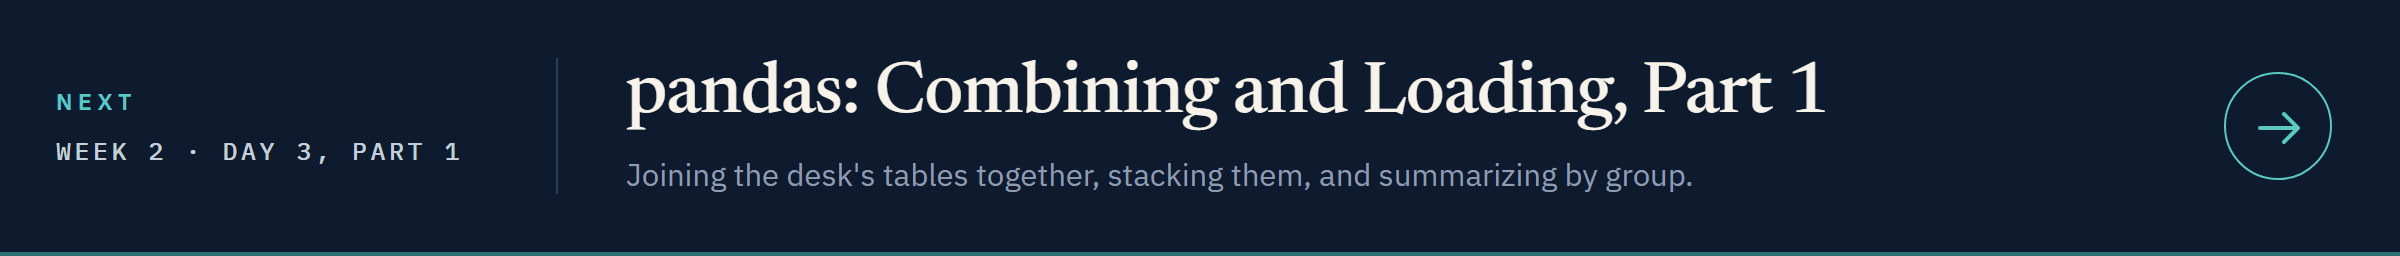](../day3/08_pandas_combining_and_loading.ipynb)

[Open Day 3, Part 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3/08_pandas_combining_and_loading.ipynb)